In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'drosophila')
pth_clf = os.path.join(pth_data, 'results', 'classifier')
pth_out = os.path.join(pth, 'figures', 'drosophila')

In [3]:
fn = os.path.join(pth_clf, 'logreg.csv')
beta = pd.read_csv(fn, index_col = 0)
beta

,beta
GSE162534,0.562046
GSE229103,4.880419
rRNAModifications,3.368317
intercept_,1.128921


In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 13429 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'leiden', 'celltype', 'GSE162534', 'GSE229103', 'rRNAModifications'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'celltype_colors', 'diffmap_evals', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

In [5]:
scaler = StandardScaler(with_mean = False)
sig = lambda x: 100 / (1 + np.exp(-x))

In [6]:
# predict branches (logreg)
X = adata.obs[beta.index[:-1]]
X = pd.DataFrame(scaler.fit_transform(X),
                 index = X.index,
                 columns = X.columns)
X['intercept_'] = 1.
prob = X.dot(beta).apply(sig)
adata.obs['Branch2'] = prob
adata.obs['Branch1'] = 100 - prob

In [7]:
ix = ['Mitotic',
      'Postmitotic',
      'Main Body',
      'Posterior',
      'Terminal',
      'Stretched',
      'Border',
      'Stalk']

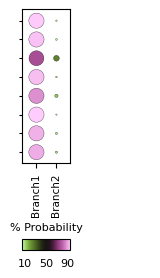

In [8]:
# signatures dotplot
fs1, fs2, var = 9, 8, ['Branch1', 'Branch2'] 
dp = sc.pl.dotplot(adata, var, 'celltype',
                   categories_order = ix,
                   expression_cutoff = 50,
                   dot_max = .8,
                   vcenter = 50,
                   cmap = 'vanimo_r',
                   figsize = (1.65, 2),
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 120,
         x_padding = .7,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']
ax_size.set_visible(False)

cax.set_title('% Probability', size = fs2, pad = 6)
cax.set_xticks([10, 50, 90])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 6)

pos_main = ax_main.get_position()
pos_color = cax.get_position()
cax.set_position([pos_main.x0,
                  pos_main.y0 - .56 * pos_main.height,
                  pos_main.width,
                  pos_color.height])

ax_main.tick_params('x', labelsize = fs2 - .5)
ax_main.set_yticklabels([])
ax_main.tick_params('y', size = 2.5)

fn = os.path.join(pth_out, 'probabilities.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [9]:
adata.write(os.path.join(pth_in, 'probabilities.h5ad'))